## **Forward solve and inversion**

An end-to-end run of the experiment: seven parameters (five tissue conductivities and the two inner interface radii), recovered from noisy surface-electrode potentials on a cylindrical limb, by backpropagating through a differentiable multigrid solve. Everything computational is imported from `neuralphysics` and correctness checks are in `tests/`.

In [25]:
# the whole API the experiment needs

import platform

import matplotlib.pyplot as plt
import numpy as np
import scipy
import torch
from IPython.display import HTML
from scipy.optimize import minimize

import neuralphysics
from neuralphysics import (
    LIMB,
    SOURCE_SPECS,
    CoefficientHierarchy,
    ElectrodeArray,
    Observation,
    add_measurement_noise,
    configure,
    dipole_centres,
    forward,
    gaussian_dipole,
    grid_at,
    interfaces_from_logits,
    laplacian_metric_3D,
    levels,
    logits_from_interfaces,
    parameter_names,
    sample_initial_parameters,
    trapezoid_weight_field,
    viz,
)

In [2]:
print(configure())
print(f"neuralphysics {neuralphysics.__version__} | torch {torch.__version__} | "
      f"numpy {np.__version__} | scipy {scipy.__version__} | python {platform.python_version()}")
print(f"default dtype {torch.get_default_dtype()} | torch threads {torch.get_num_threads()} | "
      f"{platform.platform()}")

{'dtype': 'torch.float64', 'seed': 42}
neuralphysics 0.1.0 | torch 2.5.1 | numpy 1.26.4 | scipy 1.17.1 | python 3.11.15
default dtype torch.float64 | torch threads 4 | macOS-26.6.1-arm64-arm-64bit


In [ ]:
# the forward experiment
# anything not named here is at the package default
# L = 1, z_zeta = 1, coarsening floor of 9, jacobi damping factor omega = 2/3, nu = (2, 2)
# 50 base iterations, and 100% electrode coverage on the four lateral faces

N = 65 # nodes per axis; N = 2^k + 1 must hold for the v-cycle to work
NUM_CYCLES = 8 # fixed budget - not a convergence tolerance
NOISE_PERCENT = 5.0 # noise std as a percentage of the clean field's volume RMS
NOISE_SEED = 0

In [4]:
# the inverse problem

# The starting point is run 1 of the ensemble from averaged-runs.ipynb
# it is reproduced from that notebook's seed rather than copied
# across as numbers: a transcribed start silently stops matching the moment the draw
# changes, and the point of starting here is that this run and that one begin in the
# same place. The four constants below are that notebook's and have to stay its.
#
# The outermost radius is not drawn, because skin thickness is assumed known and so
# is not recovered; it is a clinically invariant quantity in our experiment.
ENSEMBLE_SEED = 12345      # seeds the draws, and nothing else
N_RUNS = 5                 # how many were drawn there. The draws are sequential, so
                           # this must match for run 1 to be the same vector
LOG_SPREAD = np.log(3.0)   # conductivities drawn within a factor of three
RADIUS_SPREAD_MM = 1.5     # radii drawn within 1.5 mm

RUN = 1                    # which of those draws this notebook runs

MAX_ITERS = 1000 # L-BFGS-B iteration budget

# scipy's tolerances are calibrated for O(1) objectives. Here J ~ 1e-5 and
# ||grad J|| ~ 5e-6 near the solution, so the default gtol = 1e-5 is already satisfied
# at the starting point and L-BFGS-B would return after one evaluation having done
# nothing. ftol is relative to max(|f|, 1) = 1, so it is effectively absolute, and the
# default 2.2e-9 would stop while the misfit is still moving in the fourth digit.
FTOL = 1e-16
GTOL = 1e-12

SNAPSHOT_EVERY = 10     # how often to keep a predicted field for the panel figures
LIMB_RADIUS_MM = 24.0   # the physical limb radius, at r/R = 0.5
MM_PER_UNIT = LIMB_RADIUS_MM / 0.5   # normalised radius -> millimetres

In [5]:
print(f"grid     N = {N}, levels {levels(N)}")
print(f"solver   {NUM_CYCLES} V-cycles")
print(f"data     {NOISE_PERCENT}% noise (seed {NOISE_SEED})")
print(f"inverse  L-BFGS-B, <= {MAX_ITERS} iterations, ftol {FTOL:g}, gtol {GTOL:g}")

grid     N = 65, levels [65, 33, 17, 9]
solver   8 V-cycles
data     5.0% noise (seed 0)
inverse  L-BFGS-B, <= 1000 iterations, ftol 1e-16, gtol 1e-12


In [6]:
# the tissue table - read off the model
print(f"{'layer':8s} {'r/R':>13s} {'thickness':>12s} {'sigma_T':>9s} {'sigma_L':>9s}   source")
r_lo = 0.0
for nm, r_hi in zip(LIMB.layer_names, LIMB.interfaces + (0.5,)):
    sT, sL = LIMB.sigma_layers[nm]
    print(f"{nm:8s} {f'{r_lo:.3f}-{r_hi:.3f}':>13s} "
          f"{(r_hi - r_lo) * LIMB_RADIUS_MM / 0.5:9.2f} mm {sT:9.2f} {sL:9.2f}   "
          f"{'PROVISIONAL' if nm in LIMB.provisional else 'Farina, Mesin, Martina & Merletti (2004)'}")
    r_lo = r_hi

print(f"\nanisotropic layers: {sorted(LIMB.anisotropic_layers)}")
print(f"interface width  epsilon = {LIMB.epsilon:g} of L = {LIMB.epsilon * (N - 1):.2f} h at N = {N}")
print(f"geometry derived from Maksymenko et al. (2023); a {LIMB_RADIUS_MM:.0f} mm limb")

layer              r/R    thickness   sigma_T   sigma_L   source
bone       0.000-0.146      7.00 mm      0.02      0.02   Farina, Mesin, Martina & Merletti (2004)
muscle     0.146-0.417     13.00 mm      0.10      0.50   Farina, Mesin, Martina & Merletti (2004)
fat        0.417-0.479      3.00 mm      0.05      0.05   Farina, Mesin, Martina & Merletti (2004)
skin       0.479-0.500      1.00 mm      1.00      1.00   Farina, Mesin, Martina & Merletti (2004)

anisotropic layers: ['muscle']
interface width  epsilon = 0.00390625 of L = 0.25 h at N = 65
geometry derived from Maksymenko et al. (2023); a 24 mm limb


In [7]:
grid = grid_at(N)
det, rim = grid.det_J, grid.rim_stats(LIMB.shell_norm)

print(grid)
print(f"type(grid) = {type(grid)}")
print(f"rim radius  mean {rim['mean']:.5f}, spread {rim['spread']:.2e} "
      f"({rim['spread_in_h']:.3f} h)")
print(f"det(J)      min {float(det.min()):.5f}, max {float(det.max()):.5f}")
print(f"det(J)      has shape {det.shape}")
print("interfaces  " + ",  ".join(
    f"{a}/{b} {R:.2f} -> {grid.physical_shell_radius(R, LIMB.shell_norm):.4f}"
    for a, b, R in zip(LIMB.layer_names, LIMB.layer_names[1:], LIMB.interfaces)))

CylinderGrid(n=65, L=1.0, smoothing=SmoothingPolicy(iterations=100, del_t=0.2), z_zeta=1.0, mapped=True)
type(grid) = <class 'neuralphysics.grid.CylinderGrid'>
rim radius  mean 0.50144, spread 1.62e-02 (1.035 h)
det(J)      min 0.11417, max 1.11886
det(J)      has shape torch.Size([65, 65, 65])
interfaces  bone/muscle 0.15 -> 0.1463,  muscle/fat 0.42 -> 0.4179,  fat/skin 0.48 -> 0.4805


The Jacobian panel shows the four signed partials of the map $\Phi:(\xi,\eta)\mapsto(x,y)$, so we can check the map; the metric panel shows the three transverse coefficients plus $\det J$, which are what the operator consumes.

With $J = \begin{pmatrix} a & b \\ c & d\end{pmatrix}$, and $a = \partial x/\partial\xi$, the module assembles,

$$m_{xx} = \frac{z_\zeta}{\det J}(b^2 + d^2), \quad m_{yy} = \frac{z_\zeta}{\det J}(a^2 + c^2), \quad m_{xy} = -\frac{z_\zeta}{\det J}(ab + cd), \quad m_L = \frac{\det J}{z_\zeta}.$$

Squaring is what causes the metric panel to be sign-agnostic, and why $m_{xx}$ is built from the $\eta$-derivatives instead of $\xi$-ones, as it comes from inverting $J$, not from transposing it.

Note that the map has no closed form, hence, so $J$ is measured. The smoothed square-to-disc composite exists only as node positions, so every entry is a central difference approximation, $f'(t)\approx (f(t+h)-f(t-h))/2h$, taken with respect to the structured grid spacing $h = L/(N-1)$ NOT the physical (cylindrical) grid spacing!

bone       349 nodes/slice    8.3%
muscle    2492 nodes/slice   59.0%
fat        884 nodes/slice   20.9%
skin       500 nodes/slice   11.8%


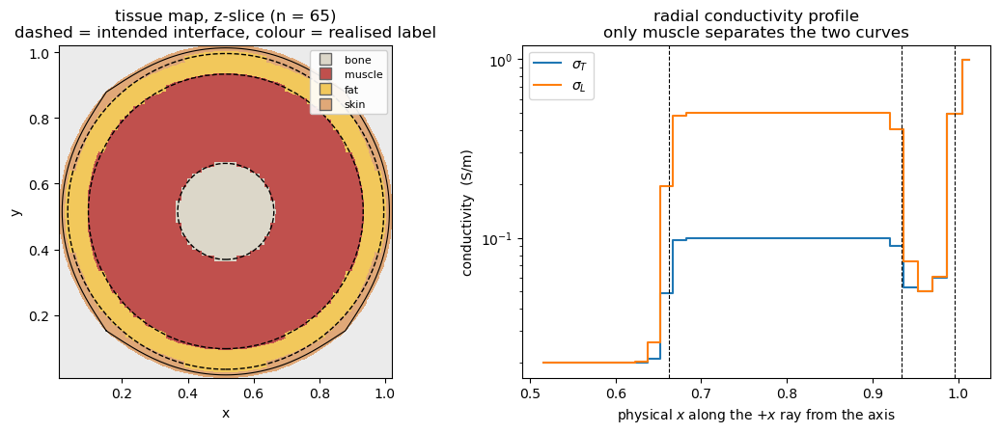

In [8]:
# a cross section of the limb, and how sigma varies along the radius from the centre
fig_tissue = viz.plot_tissue_map(grid, LIMB)

# membership is soft, so "which tissue is this node" is the dominant weight
idx = LIMB.layer_weights(grid).argmax(0)
counts = torch.bincount(idx[:, :, 0].reshape(-1), minlength=LIMB.n_layers)
for k, nm in enumerate(LIMB.layer_names):
    print(f"{nm:8s} {int(counts[k]):5d} nodes/slice  {100 * int(counts[k]) / int(counts.sum()):5.1f}%")

Two current sources, each a fibre-aligned Gaussian dipole inside muscle.

$W^\top I = 0$ is a necessary condition for the system to have any solution at all: under the insulating Neumann condition the operator has the constants in its null space and $W$ in its left null space, so a source with a net weighted charge is inadmissible. The dipole is balanced by construction and the projection is insurance.

The two sources differ in *radius*, not angle. The limb is rotationally symmetric, so two blobs at the same radius and different azimuths are rotated copies carrying the same information; the radius is what makes them independent, and the pair sits near the inner and outer edges of the band the clearance rule allows so that each is informative about a different interface. The $180^\circ$ separation is for figure legibility only.

In [9]:
WIDTH = 0.05      # the 1/e blob radius, a physical length

sources, centres = [], []
for r_norm, angle in SOURCE_SPECS:
    centres.append(dipole_centres(grid, LIMB, r_blob_norm=r_norm, angle_deg=angle))
    sources.append(gaussian_dipole(grid, LIMB, width=WIDTH,
                                   r_blob_norm=r_norm, angle_deg=angle))

W = trapezoid_weight_field(grid.n)
for s, (I, c) in enumerate(zip(sources, centres)):
    clearance = min(c["r_blob"] - c["r_inner"], c["r_outer"] - c["r_blob"])
    print(f"source {s}: r = {c['r_blob']:.4f} at {c['angle_deg']:.0f} deg, "
          f"clearance {clearance:.4f} vs 2w = {2 * WIDTH:.2f}, "
          f"peak {float(I.abs().max()):.4f}, W.I = {float((W * I).sum()):.2e}")

print(f"muscle spans [{centres[0]['r_inner']:.4f}, {centres[0]['r_outer']:.4f}], "
      f"z: source {centres[0]['cz_source']:.3f}, sink {centres[0]['cz_sink']:.3f}, "
      f"w/h = {WIDTH / grid.h:.2f}")

source 0: r = 0.2507 at 0 deg, clearance 0.1045 vs 2w = 0.10, peak 0.9893, W.I = -4.47e-16
source 1: r = 0.3129 at 180 deg, clearance 0.1050 vs 2w = 0.10, peak 0.9871, W.I = -1.29e-17
muscle spans [0.1463, 0.4179], z: source 0.370, sink 0.630, w/h = 3.20


In [10]:
print(f"I has shape {I.shape}")
c

I has shape torch.Size([65, 65, 65])


{'r_blob': 0.31289941314838005,
 'angle_deg': 180.0,
 'c_x': 0.20272558685161995,
 'c_y': 0.515625,
 'cz_source': 0.37,
 'cz_sink': 0.63,
 'r_inner': 0.14625373210728235,
 'r_outer': 0.4178678060208067}

The face coefficient tensor has shape $(6,n,n,n)$: six faces per node. The operator is assembled in flux form, so each node's equation is a sum of fluxes through its six faces, and the homogeneous Neumann condition is imposed by omitting the boundary faces from that sum.

Each face coefficient is a product of two averages taken separately — a *harmonic* mean of the conductivities, which is where the interface physics lives, and an *arithmetic* mean of the metric fields.

In [11]:
coeff_true = CoefficientHierarchy.from_vectors(LIMB, N)

print(f"levels {coeff_true.levels} | n_fine {coeff_true.n_fine} | L {coeff_true.L} | "
      f"requires_grad {coeff_true.requires_grad}")
for n in coeff_true.levels:
    f = coeff_true.faces[n]
    print(f"  n = {n:3d}  faces {tuple(f.shape)}  sigma_T {tuple(coeff_true.sigma_T[n].shape)}  "
          f"face coeff range [{float(f.min()):.4f}, {float(f.max()):.4f}]")

levels (65, 33, 17, 9) | n_fine 65 | L 1.0 | requires_grad False
  n =  65  faces (6, 65, 65, 65)  sigma_T (65, 65, 65)  face coeff range [0.0161, 2.0988]
  n =  33  faces (6, 33, 33, 33)  sigma_T (33, 33, 33)  face coeff range [0.0163, 1.7411]
  n =  17  faces (6, 17, 17, 17)  sigma_T (17, 17, 17)  face coeff range [0.0170, 1.3345]
  n =   9  faces (6, 9, 9, 9)  sigma_T (9, 9, 9)  face coeff range [0.0173, 1.1315]


In [12]:
A = lambda f: laplacian_metric_3D(f, grid.h, coeff_true.faces[grid.n],
                                  coeff_true.metric[grid.n], coeff_true.sigma_T[grid.n])

# how fast the V-cycle converges: a fixed count, not a tolerance
prev = None
for k in range(1, NUM_CYCLES + 1):
    phi_true = forward(sources[0], coeff_true, num_cycles=k)
    r = float((sources[0] - A(phi_true)).norm() / sources[0].norm())
    print(f"  cycle {k}: ||I - A phi|| / ||I|| = {r:.4e}"
          + ("" if prev is None else f"   factor {r / prev:.3f}"))
    prev = r

print(f"\nphi range [{float(phi_true.min()):.3e}, {float(phi_true.max()):.3e}], "
      f"gauge W.phi = {float((W * phi_true).sum()):.2e}")

  cycle 1: ||I - A phi|| / ||I|| = 4.0622e-01
  cycle 2: ||I - A phi|| / ||I|| = 1.9095e-01   factor 0.470
  cycle 3: ||I - A phi|| / ||I|| = 9.7683e-02   factor 0.512
  cycle 4: ||I - A phi|| / ||I|| = 5.8873e-02   factor 0.603
  cycle 5: ||I - A phi|| / ||I|| = 3.3199e-02   factor 0.564
  cycle 6: ||I - A phi|| / ||I|| = 2.1010e-02   factor 0.633
  cycle 7: ||I - A phi|| / ||I|| = 1.2901e-02   factor 0.614
  cycle 8: ||I - A phi|| / ||I|| = 8.2618e-03   factor 0.640

phi range [-5.953e-03, 5.953e-03], gauge W.phi = -4.08e-17


In [13]:
array = ElectrodeArray()          # full coverage of the four lateral faces
mask_nodes = array.mask(grid.n)

observations = []
for s, I in enumerate(sources):
    phi_s = phi_true if s == 0 else forward(I, coeff_true, num_cycles=NUM_CYCLES)
    phi_obs, noise_stats = add_measurement_noise(phi_s, NOISE_PERCENT, NOISE_SEED + s)
    observations.append(Observation(phi=phi_obs, mask=mask_nodes, grid=grid))
    print(f"noise  source {s}: {NOISE_PERCENT:.1f}% of RMS {noise_stats['rms']:.3e} -> "
          f"std {noise_stats['noise_std']:.3e}, realised SNR {noise_stats['snr']:.2f}")

obs = observations[0]      # the field and residual figures are drawn for source 0
print(f"array  step {array.step}, coverage {array.coverage(grid.n):.3f}, "
      f"{int(obs.mask.sum())} electrodes of {grid.n ** 3} nodes")

noise  source 0: 5.0% of RMS 5.161e-04 -> std 2.581e-05, realised SNR 20.00
noise  source 1: 5.0% of RMS 4.928e-04 -> std 2.464e-05, realised SNR 20.02
array  step 1, coverage 1.000, 16640 electrodes of 274625 nodes


In [14]:
# the slider walks along the fibre axis, one panel per source
fig_anim, anim = viz.animate_slices(sources, [o.phi for o in observations], grid, LIMB,
                                    noise_percent=NOISE_PERCENT)
plt.close(fig_anim)
HTML(anim.to_jshtml())

Animation size has reached 21258481 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


In [15]:
param_names = list(parameter_names(LIMB))
sigma_true = torch.tensor([LIMB.sigma_layers["bone"][0],
                           LIMB.sigma_layers["muscle"][0],
                           LIMB.sigma_layers["muscle"][1],
                           LIMB.sigma_layers["fat"][0],
                           LIMB.sigma_layers["skin"][0]])

n_sigma = len(param_names)
R_OUTER = LIMB.interfaces[-1]          # fat/skin surface: fixed, not recovered

# the starting point, redrawn from averaged-runs.ipynb's seed. The runs are drawn in
# sequence from one generator, so drawing N_RUNS of them and taking the RUN-th is the
# same vector that notebook's run 1 started from -- which is why N_RUNS is carried
# here at all, in a notebook that makes a single run. Both halves of theta come from
# the draw: the five log-conductivities and the two logits, so the geometry and the
# conductivities start where run 1 started and not merely near it.
starts = sample_initial_parameters(LIMB, N_RUNS, seed=ENSEMBLE_SEED,
                                   log_spread=LOG_SPREAD,
                                   radius_spread=RADIUS_SPREAD_MM / MM_PER_UNIT)
theta_ref = starts[RUN - 1]
rho_ref = theta_ref[:n_sigma]

u_true = logits_from_interfaces(LIMB.interfaces)
theta_true = torch.cat([torch.log(sigma_true), u_true])


def unpack(theta):
    """(7,) parameters -> (sigma_T, sigma_L, interface radii).

    The first five are log-conductivities. bone, fat and skin appear in both vectors as
    the same tensor element, so an isotropic tissue's gradient accumulates into one
    scalar; muscle splits into T and L.

    The last two are softmax logits for the two inner interfaces. They are
    unconstrained: any real pair gives 0 < R_1 < R_2 < R_OUTER, so L-BFGS-B needs no
    bounds and no ordering constraint.
    """
    s = theta[:n_sigma].exp()
    return (torch.stack([s[0], s[1], s[3], s[4]]),      # bone, muscle_T, fat, skin
            torch.stack([s[0], s[2], s[3], s[4]]),      # bone, muscle_L, fat, skin
            interfaces_from_logits(theta[n_sigma:], R_OUTER))


def thicknesses_mm(interfaces):
    """Interface radii -> the four layer thicknesses in mm, skin closed off at the rim.

    A thickness is the anatomical quantity; a radius is a coordinate. Skin appears here
    even though it is not recovered, because it is the difference between R_OUTER and
    the rim and so is the one thickness fixed by assumption.
    """
    R = torch.as_tensor(interfaces).reshape(-1)
    edges = torch.cat([torch.zeros_like(R[:1]), R, torch.full_like(R[:1], 0.5)])
    return torch.diff(edges) * (LIMB_RADIUS_MM / 0.5)


sT_ref, sL_ref = LIMB.sigma_vectors()
sT_chk, sL_chk, R_chk = unpack(theta_true)
print(f"layers {LIMB.layer_names} | params {param_names} + logits u_1, u_2")
print(f"unpack(theta_true) reproduces the tissue table: "
      f"{torch.allclose(sT_chk, sT_ref) and torch.allclose(sL_chk, sL_ref)}")
print(f"          and round-trips the geometry: "
      f"{torch.allclose(R_chk, torch.as_tensor(LIMB.interfaces))}")
print(f"starting from run {RUN} of {N_RUNS} drawn at seed {ENSEMBLE_SEED}")
print(f"start sigma {[f'{v:.3f}' for v in rho_ref.exp().tolist()]}")
print(f"start  {[f'{v:.2f}' for v in thicknesses_mm(unpack(theta_ref)[2]).tolist()]} mm")
print(f"true   {[f'{v:.2f}' for v in thicknesses_mm(LIMB.interfaces).tolist()]} mm")

layers ('bone', 'muscle', 'fat', 'skin') | params ['bone', 'muscle_T', 'muscle_L', 'fat', 'skin'] + logits u_1, u_2
unpack(theta_true) reproduces the tissue table: True
          and round-trips the geometry: True
starting from run 1 of 5 drawn at seed 12345
start sigma ['0.011', '0.067', '0.961', '0.074', '0.787']
start  ['6.50', '13.80', '2.71', '1.00'] mm
true   ['7.00', '13.00', '3.00', '1.00'] mm


In [16]:
mask = obs.mask
phi_obs_norm = float(torch.sqrt(sum((o.phi[mask] ** 2).sum() for o in observations)))

loss_history, sigma_history, interface_history = [], [], []
geometry_snapshots, phi_snapshots = [], []

print(f"{int(mask.sum())} electrode nodes | ||phi_obs|| on the mask = {phi_obs_norm:.4e}")
print(f"recovering {n_sigma} conductivities and 2 interface radii, "
      f"{n_sigma + 2} parameters in all")

16640 electrode nodes | ||phi_obs|| on the mask = 4.9419e-02
recovering 5 conductivities and 2 interface radii, 7 parameters in all


In [17]:
def objective(theta_np):
    """(7,) numpy parameters -> (J, dJ/dtheta), the (fun, jac) pair scipy wants.

    The hierarchy is rebuilt with soft membership at the current radii, so the same
    backward pass that returns dJ/dsigma returns dJ/du. That derivative is a shape
    derivative -- a boundary integral weighted by the conductivity jump -- obtained
    with no new derivation.
    """
    theta = torch.tensor(theta_np, dtype=torch.float64, requires_grad=True)
    sT_vec, sL_vec, R = unpack(theta)

    coeff = CoefficientHierarchy.from_vectors(LIMB, N, sT_vec, sL_vec, interfaces=R)
    preds = [forward(I, coeff, num_cycles=NUM_CYCLES) for I in sources]

    loss = sum(0.5 * ((p - o.phi)[mask] ** 2).sum()
               for p, o in zip(preds, observations))
    loss.backward()

    k = len(loss_history)
    loss_history.append(loss.item())
    sigma_history.append(theta[:n_sigma].detach().exp().clone())
    interface_history.append(R.detach().clone())
    geometry_snapshots.append((k, sT_vec.detach().clone(), R.detach().clone()))

    if k % SNAPSHOT_EVERY == 0:
        rel = float(torch.sqrt(sum(((p.detach() - o.phi)[mask] ** 2).sum()
                                   for p, o in zip(preds, observations))) / phi_obs_norm)
        phi_snapshots.append((k, preds[0].detach().clone(), rel))

    if k % 5 == 0:
        s = theta[:n_sigma].detach().exp()
        print(f" eval {k:3d}: J = {loss.item():.4e}   "
              + "  ".join(f"{nm} = {v:.4f}" for nm, v in zip(param_names, s)))
        print(f"           thickness/mm "
              + "  ".join(f"{nm} = {v:.2f}" for nm, v
                          in zip(LIMB.layer_names, thicknesses_mm(R.detach()))))

    return loss.item(), theta.grad.detach().numpy().copy()

In [18]:
f0, g0 = objective(theta_ref.numpy())
print(f"||dJ/drho|| = {np.linalg.norm(g0[:n_sigma]):.4e}, "
      f"||dJ/du|| = {np.linalg.norm(g0[n_sigma:]):.4e}, "
      f"ratio {np.linalg.norm(g0[n_sigma:]) / np.linalg.norm(g0[:n_sigma]):.3f}")

# that probe recorded an iterate; drop it so the histories begin at the optimiser's
# own first evaluation and the figures' x-axis is an honest evaluation count
for record in (loss_history, sigma_history, interface_history,
               geometry_snapshots, phi_snapshots):
    record.clear()

 eval   0: J = 2.9098e-04   bone = 0.0110  muscle_T = 0.0669  muscle_L = 0.9610  fat = 0.0736  skin = 0.7872
           thickness/mm bone = 6.50  muscle = 13.80  fat = 2.71  skin = 1.00
||dJ/drho|| = 6.9298e-04, ||dJ/du|| = 2.0042e-04, ratio 0.289


In [19]:
result = minimize(objective, theta_ref.numpy(), jac=True, method="L-BFGS-B",
                  options={"maxiter": MAX_ITERS, "maxfun": 4 * MAX_ITERS,
                           "ftol": FTOL, "gtol": GTOL})

sigma_history = torch.stack(sigma_history)
interface_history = torch.stack(interface_history)

theta_rec = torch.tensor(result.x)
sigma_rec = theta_rec[:n_sigma].exp()
R_rec = interfaces_from_logits(theta_rec[n_sigma:], R_OUTER)
print(f"\nL-BFGS-B: {result.message}")
print(f"  iterations {result.nit}, evaluations {result.nfev}, "
      f"final ||grad J|| = {np.linalg.norm(result.jac):.3e}")
if result.nit >= MAX_ITERS:
    print("  WARNING: hit the iteration cap - this iterate is not a converged minimiser")

print("\nrecovered conductivities:")
for nm, r, t in zip(param_names, sigma_rec, sigma_true):
    print(f"  {nm:9s} {r.item():8.4f}   true {t.item():8.4f}   "
          f"rel err {abs(r.item() - t.item()) / t.item():7.2%}")

print("\nrecovered thicknesses:")
for nm, r, t in zip(LIMB.layer_names, thicknesses_mm(R_rec),
                    thicknesses_mm(LIMB.interfaces)):
    print(f"  {nm:9s} {r.item():8.2f} mm  true {t.item():8.2f} mm   "
          f"rel err {abs(r.item() - t.item()) / t.item():7.2%}"
          + ("   (fixed, not recovered)" if nm == LIMB.layer_names[-1] else ""))

 eval   0: J = 2.9098e-04   bone = 0.0110  muscle_T = 0.0669  muscle_L = 0.9610  fat = 0.0736  skin = 0.7872
           thickness/mm bone = 6.50  muscle = 13.80  fat = 2.71  skin = 1.00
 eval   5: J = 1.9435e-05   bone = 0.0110  muscle_T = 0.0793  muscle_L = 0.5601  fat = 0.0743  skin = 0.7008
           thickness/mm bone = 7.04  muscle = 12.98  fat = 2.98  skin = 1.00
 eval  10: J = 1.0676e-05   bone = 0.0110  muscle_T = 0.1097  muscle_L = 0.5244  fat = 0.0708  skin = 1.0126
           thickness/mm bone = 7.18  muscle = 12.84  fat = 2.98  skin = 1.00
 eval  15: J = 1.0515e-05   bone = 0.0111  muscle_T = 0.0970  muscle_L = 0.4822  fat = 0.0636  skin = 1.1099
           thickness/mm bone = 6.60  muscle = 13.35  fat = 3.05  skin = 1.00
 eval  20: J = 1.0494e-05   bone = 0.0111  muscle_T = 0.0924  muscle_L = 0.4661  fat = 0.0588  skin = 1.1283
           thickness/mm bone = 6.81  muscle = 13.28  fat = 2.91  skin = 1.00
 eval  25: J = 1.0490e-05   bone = 0.0110  muscle_T = 0.0940  muscle_L

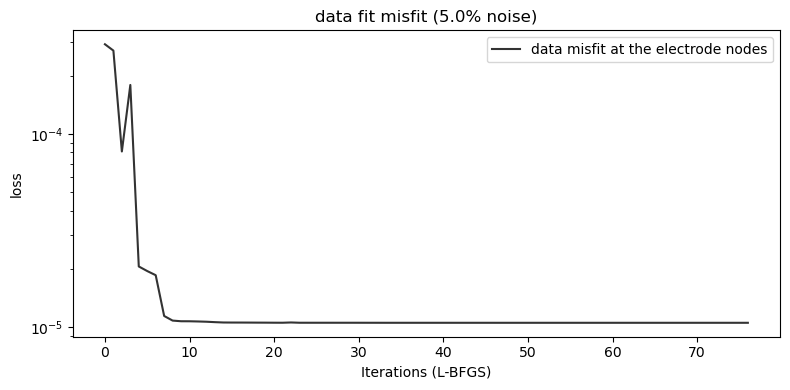

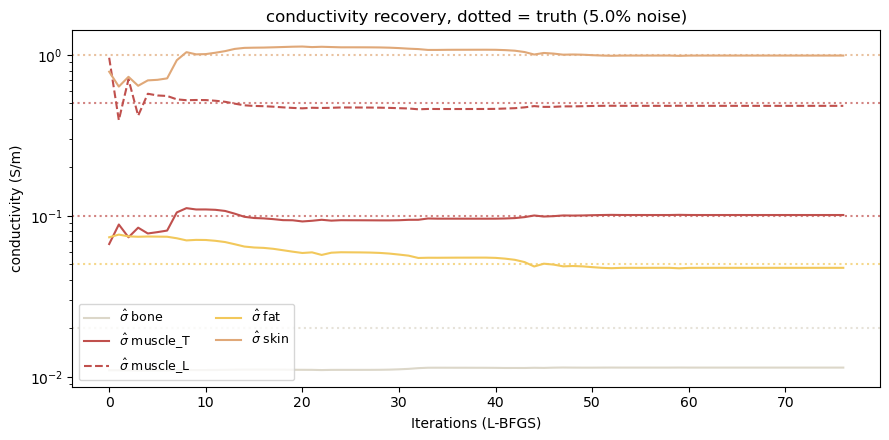

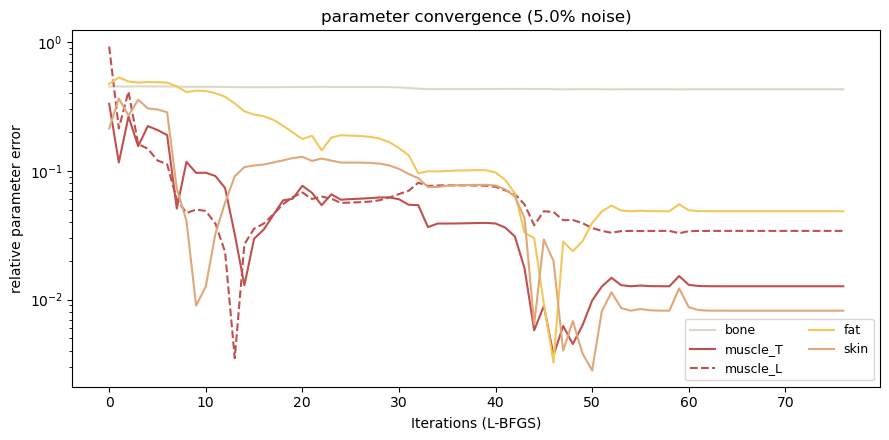

In [20]:
fig_loss, fig_sigma, fig_error = viz.plot_convergence(
    sigma_history, sigma_true, param_names,
    data_loss=loss_history, noise_percent=NOISE_PERCENT)

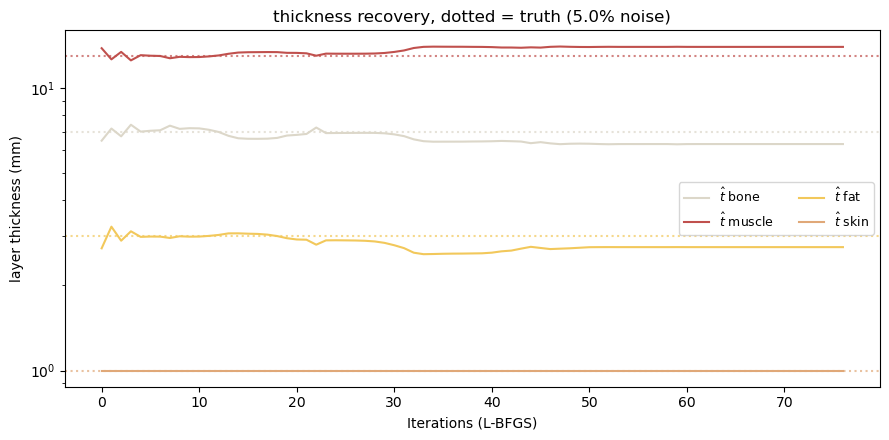

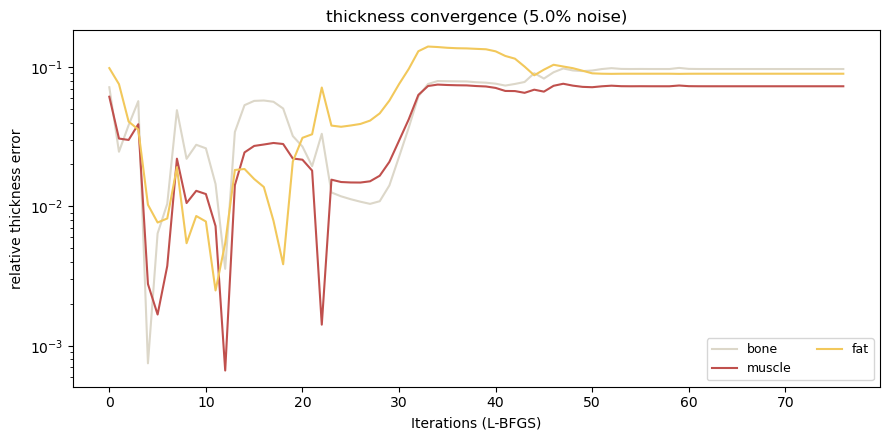

In [21]:
fig_thick, fig_thick_err = viz.plot_radius_convergence(
    interface_history, LIMB.interfaces, LIMB.layer_names,
    noise_percent=NOISE_PERCENT, limb_radius=LIMB_RADIUS_MM, unit="mm")

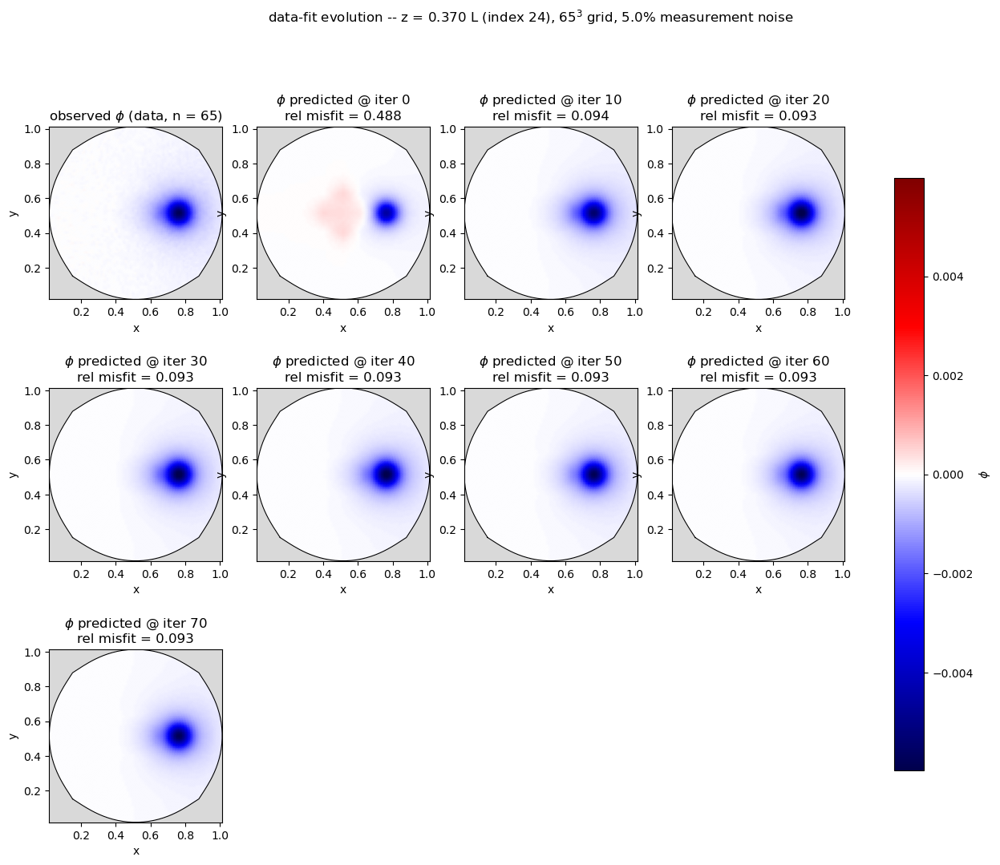

In [22]:
z_fraction = 0.37

fig_fields = viz.plot_field_panels(obs, phi_snapshots, z_fraction=z_fraction,
                                   noise_percent=NOISE_PERCENT)

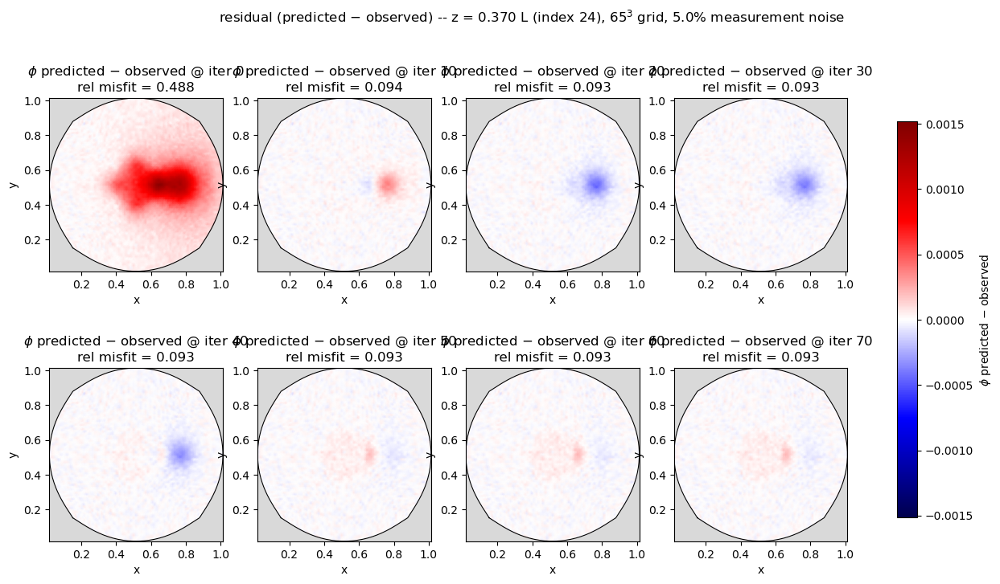

In [23]:
fig_residual = viz.plot_residual_panels(obs, phi_snapshots, z_fraction=z_fraction,
                                        noise_percent=NOISE_PERCENT)

77 iterates recorded, drawing every 4 -> 21 panels


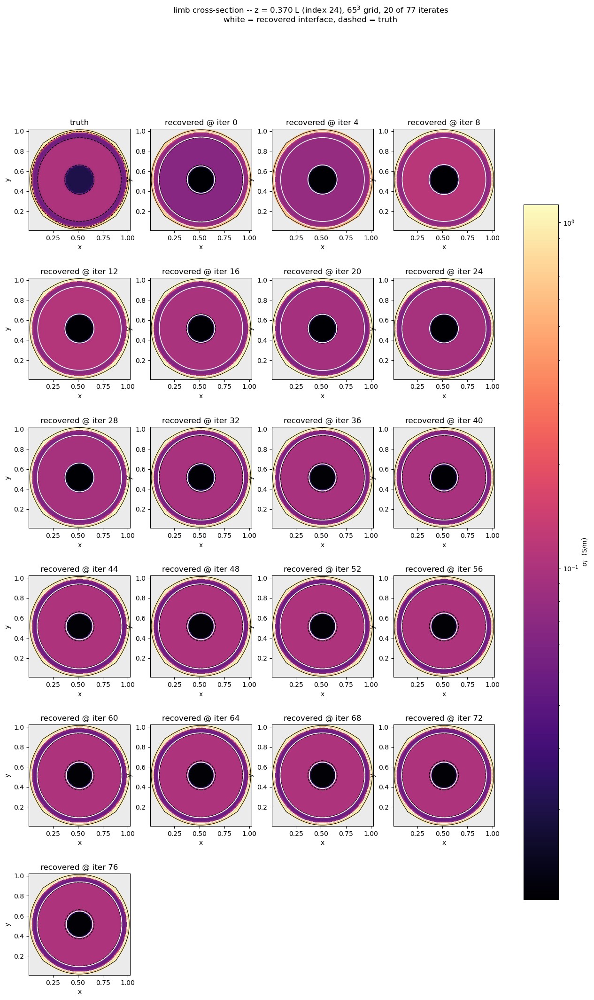

In [24]:
# every iterate was recorded (seven scalars each); thin here so the figure stays readable
geometry_every = max(1, -(-len(geometry_snapshots) // 20))

fig_geometry = viz.plot_geometry_panels(grid, LIMB, geometry_snapshots, LIMB.epsilon,
                                        z_fraction=z_fraction,
                                        snapshot_every=geometry_every)

print(f"{len(geometry_snapshots)} iterates recorded, "
      f"drawing every {geometry_every} -> {1 + len(geometry_snapshots[::geometry_every])} panels")

#### Caveats

**The forward solve is a budget, not a convergence.** Eight V-cycles leave a relative residual of about $5\times10^{-3}$ at $N = 65$, so $\phi$ satisfies the discrete PDE to a little over two digits and no inversion result can be sharper than that. The solver is not stalling — it reaches $1.2\times10^{-4}$ at sixteen cycles and $9.0\times10^{-8}$ at thirty-two — but the contraction factor degrades monotonically over the eight cycles actually used, from about $0.46$ to about $0.60$, which is the signature of a coarse-grid correction progressively less able to remove the remaining smooth error. The residual cell above prints the run's own numbers; these are what they were when this text was written.

**The gradient is approximate.** `probe_diagonal` runs under `no_grad`, so the diagonal used by the smoother is frozen with respect to the parameters and autograd differentiates a slightly different iteration from the one that ran: the discarded term is the one in $\mathrm{d}D^{-1}/\mathrm{d}\sigma$. Because that term multiplies the residual, the discrepancy shrinks as the solve converges and does not vanish at a finite cycle budget. Its size at these settings is not measured in this notebook.